|Код|Значення|Хто формує|
|---|--------|------|
|400|Дані в запиті неприйнятні для прикладної логіки.|Наш код: ми свідомо повертаємо його, коли predict() знайшла помилку у вхідних даних.|
|422|Тіло запиту не відповідає оголошеній структурі.|FastAPI автоматично, ще до виклику нашої функції.|
|500|Внутрішня помилка сервера.|Сервер, коли в коді виникла необроблена помилка.|

fastapi==0.143.2  
uvicorn==0.52.4

PS C:\Users\Nicolas\Desktop\Магістратура\ПСМН> uvicorn app:app --reload  
INFO:     Will watch for changes in these directories: ['C:\\Users\\Nicolas\\Desktop\\Магістратура\\ПСМН']  
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)  
INFO:     Started reloader process [17652] using WatchFiles  
INFO:     Started server process [20504]  
INFO:     Waiting for application startup.  
INFO:     Application startup complete.  

In [1]:
import pandas as pd
from predict import predict

records = pd.read_csv("new_records.csv")
print(records.head(2).to_json(orient="records"))

[{"age":45,"job":"blue-collar","marital":"single","education":"basic.4y","default":"no","housing":"no","loan":"no","contact":"cellular","month":"may","day_of_week":"wed","duration":223,"campaign":1,"pdays":null,"previous":1,"poutcome":"failure","emp.var.rate":-1.8,"cons.price.idx":92.893,"cons.conf.idx":-46.2,"euribor3m":1.281,"nr.employed":5099.1,"no_previous_contact":1},{"age":32,"job":"blue-collar","marital":"married","education":"basic.6y","default":"unknown","housing":"yes","loan":"no","contact":"telephone","month":"may","day_of_week":"mon","duration":36,"campaign":1,"pdays":null,"previous":0,"poutcome":"nonexistent","emp.var.rate":1.1,"cons.price.idx":93.994,"cons.conf.idx":-36.4,"euribor3m":4.858,"nr.employed":5191.0,"no_previous_contact":1}]


```json
[
  {
    "probability": 0.077,
    "decision": 0
  },
  {
    "probability": 0.024,
    "decision": 0
  }
]

In [2]:
predict(records.head(2))

,probability,decision
0,0.077,0
1,0.024,0


Отримані результати збігаються.

```json
{
  "status": "ok",
  "model": "LogisticRegression",
  "threshold": 0.21,
  "created": "2026-10-15"
}

Модель і її опис завантажуються на верхньому рівні predict.py, тобто один раз під час імпорту, коли стартує сервер. 

In [4]:
bad = records.head(1).drop(columns=["age", "job"])
print(bad.to_json(orient="records"))

[{"marital":"single","education":"basic.4y","default":"no","housing":"no","loan":"no","contact":"cellular","month":"may","day_of_week":"wed","duration":223,"campaign":1,"pdays":null,"previous":1,"poutcome":"failure","emp.var.rate":-1.8,"cons.price.idx":92.893,"cons.conf.idx":-46.2,"euribor3m":1.281,"nr.employed":5099.1,"no_previous_contact":1}]


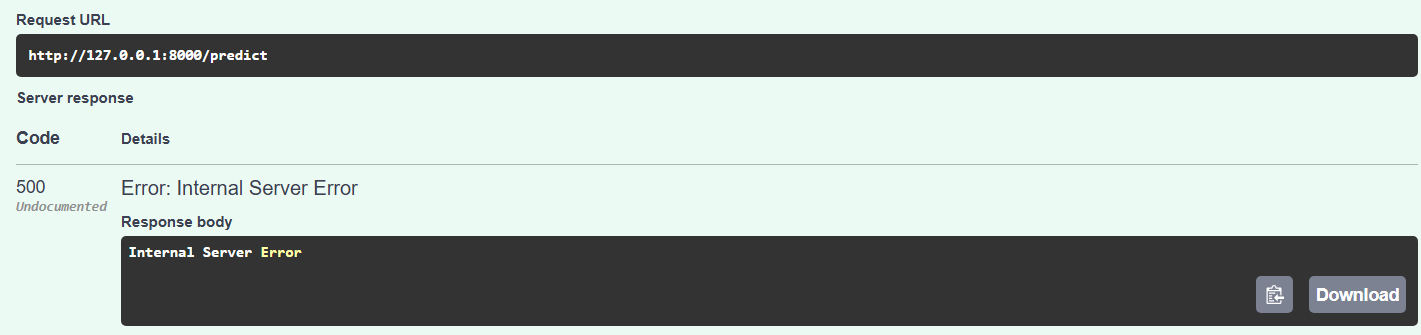

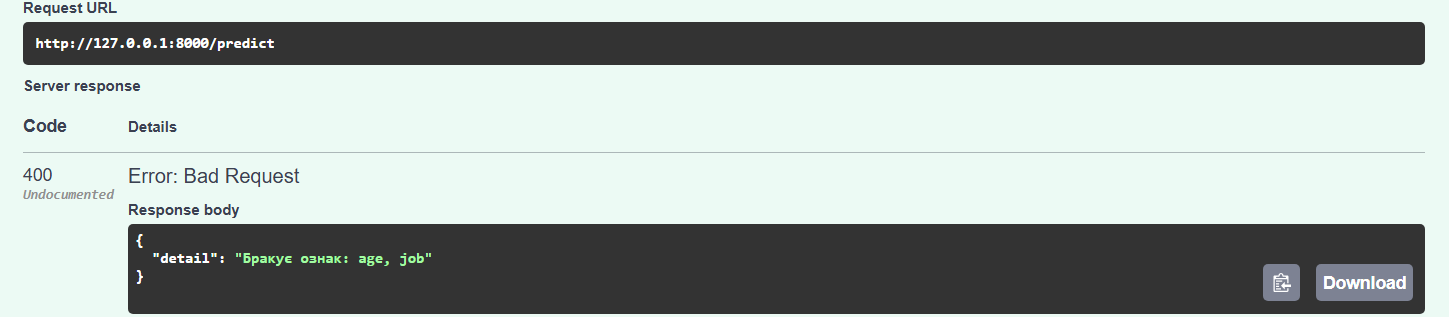

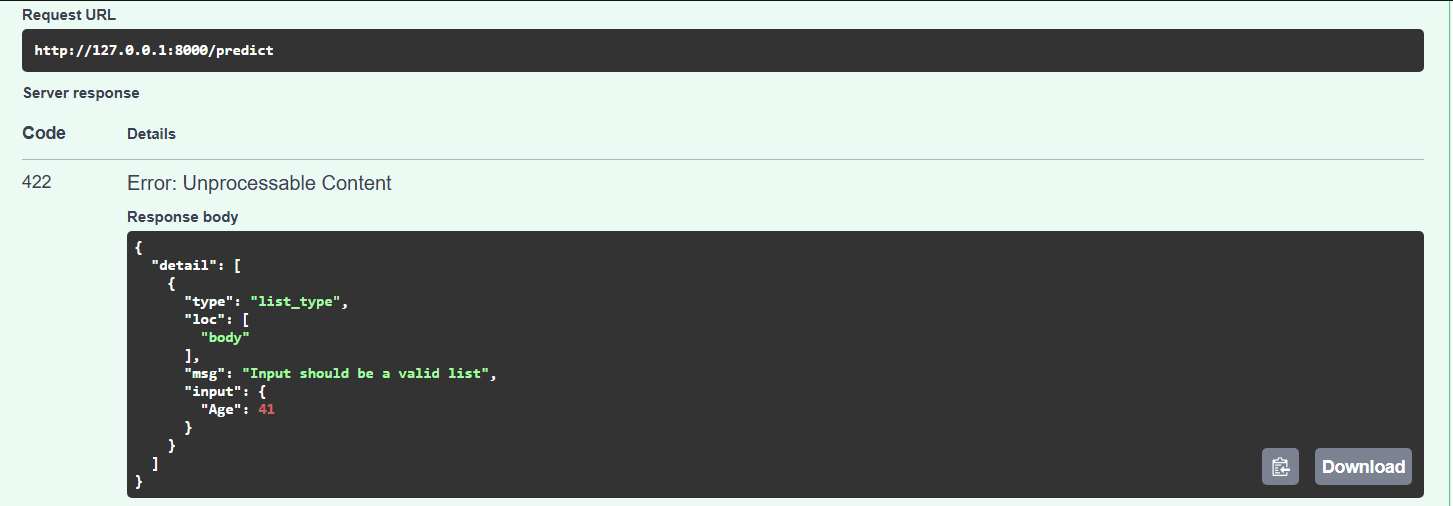

422 - це перевірка форми HTTP-входу (Fast API), а 400 - перевірка даних прикладною логікою (app.py).

In [8]:
import pandas as pd
import requests
from predict import predict

URL = "http://127.0.0.1:8000"
records = pd.read_csv("new_records.csv")
records["pdays"] = records["pdays"].fillna(-1)

response = requests.post(f"{URL}/predict",
                         json=records.to_dict(orient="records"))
service = pd.DataFrame(response.json())
threshold = requests.get(f"{URL}/health").json()["threshold"]
local = predict(records)
service

,probability,decision
0,0.085,0
1,0.026,0
2,0.047,0
3,0.051,0
4,0.043,0


In [11]:
# 1. Успішний запит
assert response.status_code == 200

# 2. Імовірності в межах [0, 1]
assert service["probability"].between(0, 1).all()

# 3. Рішення відповідає порогу
clear = (service["probability"] - threshold).abs() > 0.0005
expected = (service["probability"] >= threshold).astype(int)
assert (service["decision"] == expected)[clear].all()

# 4. Збіг із локальним викликом predict()
assert (service.values == local.values).all()

# 5. Запис без обов'язкової ознаки дає 400
bad = records.drop(columns=["age"]).to_dict(orient="records")
bad_response = requests.post(f"{URL}/predict", json=bad)
assert bad_response.status_code == 400

print("Усі 5 перевірок пройдено")

AssertionError: 

Початковий файл проходить всі 5 перевірок. Після прибрання try except отримуємо AssertionError для перевірки 5.

In [16]:
import fastapi
import uvicorn

print("fastapi==" + fastapi.__version__)
print("uvicorn==" + uvicorn.__version__)
print("requests==" + requests.__version__)

fastapi==0.143.2
uvicorn==0.52.4
requests==2.32.5


Тепер модель є доступною як локальне API, до якого може під’єднатися будь-який застосунок. API потрібен для надання доступу до функціоналу з одночасним прихованням самої моделі та сообливостей її роботи. Зовнішній клієнт може надсилати запити та отримувати на них відповіді, а також через GET отримати метадані моделі. Обмеженням є відсутність загального доступу через мережу Інтернет.